In [3]:
# libs
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd


# Original RF

In [4]:
# read data
df = pd.read_csv(r'D:\STUDY\internship\code_internship\dataset\sensor\data_prepared.csv')
df.head()

,material,stroke,osc_freq,force,cycle,coe,Absolute Energy,Amplitude,ASL,Average Frequency,Initiation Frequency,Parametric 1,Parametric 2,Peak Frequency,Reverberation Frequency,Threshold,stage
0,steel-glass,100,10,10,1,0.023768,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one
1,steel-glass,100,10,10,2,0.024692,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one
2,steel-glass,100,10,10,3,0.024137,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one
3,steel-glass,100,10,10,4,0.024139,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one
4,steel-glass,100,10,10,5,0.023798,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,one


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4838 entries, 0 to 4837
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   material                 4838 non-null   object 
 1   stroke                   4838 non-null   int64  
 2   osc_freq                 4838 non-null   int64  
 3   force                    4838 non-null   int64  
 4   cycle                    4838 non-null   int64  
 5   coe                      4838 non-null   float64
 6   Absolute Energy          4838 non-null   float64
 7   Amplitude                4838 non-null   float64
 8   ASL                      4838 non-null   float64
 9   Average Frequency        4838 non-null   float64
 10  Initiation Frequency     4838 non-null   float64
 11  Parametric 1             4838 non-null   float64
 12  Parametric 2             4838 non-null   float64
 13  Peak Frequency           4838 non-null   float64
 14  Reverberation Frequency 

In [6]:
df.describe()

,stroke,osc_freq,force,cycle,coe,Absolute Energy,Amplitude,ASL,Average Frequency,Initiation Frequency,Parametric 1,Parametric 2,Peak Frequency,Reverberation Frequency,Threshold
count,4838.0,4838.000000,4838.000000,4838.000000,4838.000000,4.838000e+03,4838.000000,4838.000000,4838.000000,4838.000000,4838.000000,4838.000000,4838.000000,4838.000000,4838.000000
mean,100.0,14.640347,11.488218,390.271393,0.528342,4.096229e+03,26.539702,17.661375,25.252931,102.700762,0.022984,0.206008,14.531694,7.192826,21.687061
std,0.0,4.016304,3.113351,266.878013,0.300984,5.690821e+04,15.829699,11.952416,51.564936,147.110292,0.015583,0.131820,9.025587,6.349208,12.594798
min,100.0,10.000000,5.000000,1.000000,0.004419,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,100.0,10.000000,10.000000,173.000000,0.193288,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,100.0,15.000000,10.000000,346.000000,0.587128,5.409019e+01,33.142857,19.000000,11.833333,24.369318,0.026469,0.247706,19.000000,7.333333,29.000000
75%,100.0,20.000000,15.000000,566.000000,0.744997,3.114888e+02,36.909091,26.121528,18.500000,158.250000,0.035153,0.317087,21.000000,11.181818,29.000000
max,100.0,20.000000,15.000000,1129.000000,1.013084,1.504584e+06,59.000000,57.428571,1000.000000,1000.000000,0.059991,0.434889,51.200000,58.000000,29.000000


In [7]:
# chech if the data is balanced
columns_to_check = ['Threshold', 'stage']

for col in columns_to_check:
    
    print(df[col].value_counts(dropna=False))  
    print("------------------")

Threshold
29    3618
0     1220
Name: count, dtype: int64
------------------
stage
four     1471
five     1109
one      1093
two       746
three     419
Name: count, dtype: int64
------------------


In [8]:
# features and labels
X = df.drop(columns=['material', 'stroke', 'stage', 'cycle'])
y = df['stage']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y) # use stratufy to make sure the test data includes all labels.

In [9]:
# establish model
rf = RandomForestClassifier(
    n_estimators=100,  # the number of trees in the forest
    max_depth=3,       # the maximum depth of each tree
    random_state=42,   # random seed for reproducibility
    n_jobs=-1         # use all available cpus cores for parallel processing
)

Accuracy: 0.67

Classification report of original model:
              precision    recall  f1-score   support

        five       0.59      0.39      0.47       333
        four       0.56      0.94      0.70       441
         one       0.91      1.00      0.95       328
       three       0.00      0.00      0.00       126
         two       0.73      0.46      0.56       224

    accuracy                           0.67      1452
   macro avg       0.56      0.56      0.54      1452
weighted avg       0.63      0.67      0.62      1452


Feature importance of original model:
Absolute Energy            0.149339
ASL                        0.138248
Amplitude                  0.126762
coe                        0.124947
Parametric 2               0.106703
Parametric 1               0.083219
Peak Frequency             0.080179
Initiation Frequency       0.074112
osc_freq                   0.045956
Threshold                  0.028442
Average Frequency          0.021898
force              

d:\Python\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Python\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Python\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


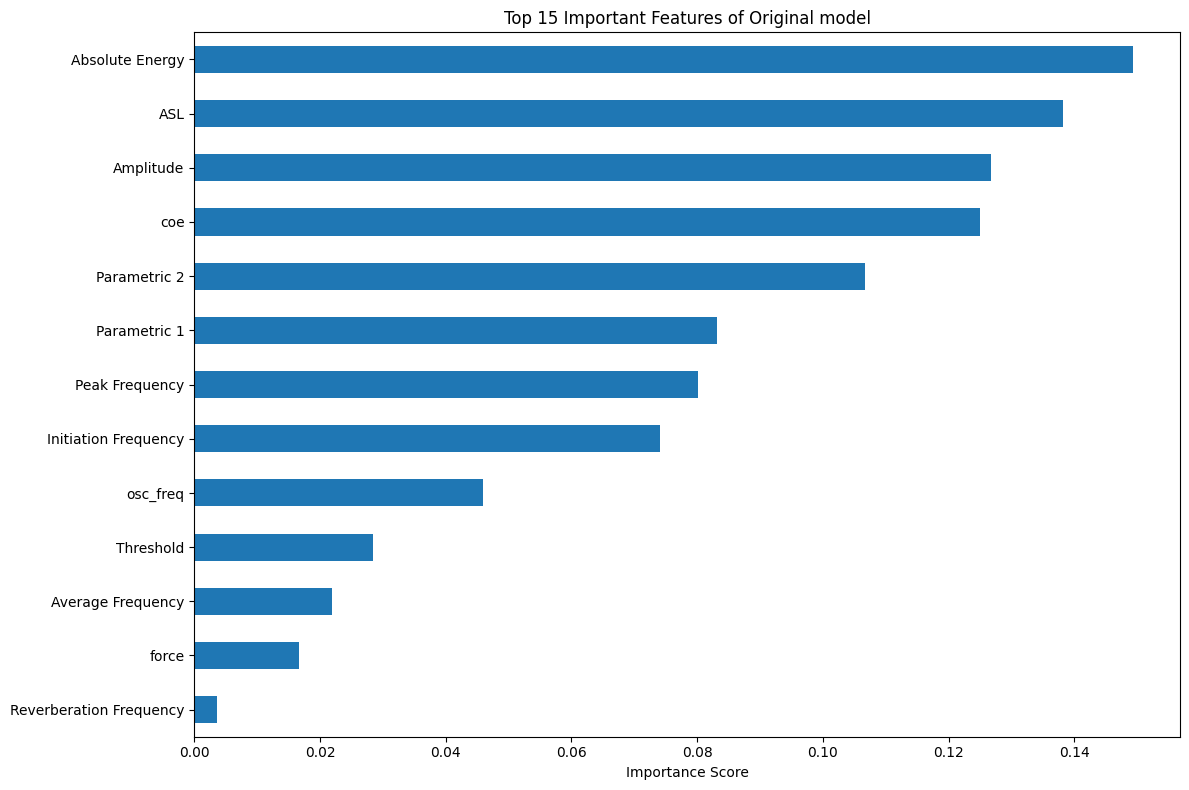

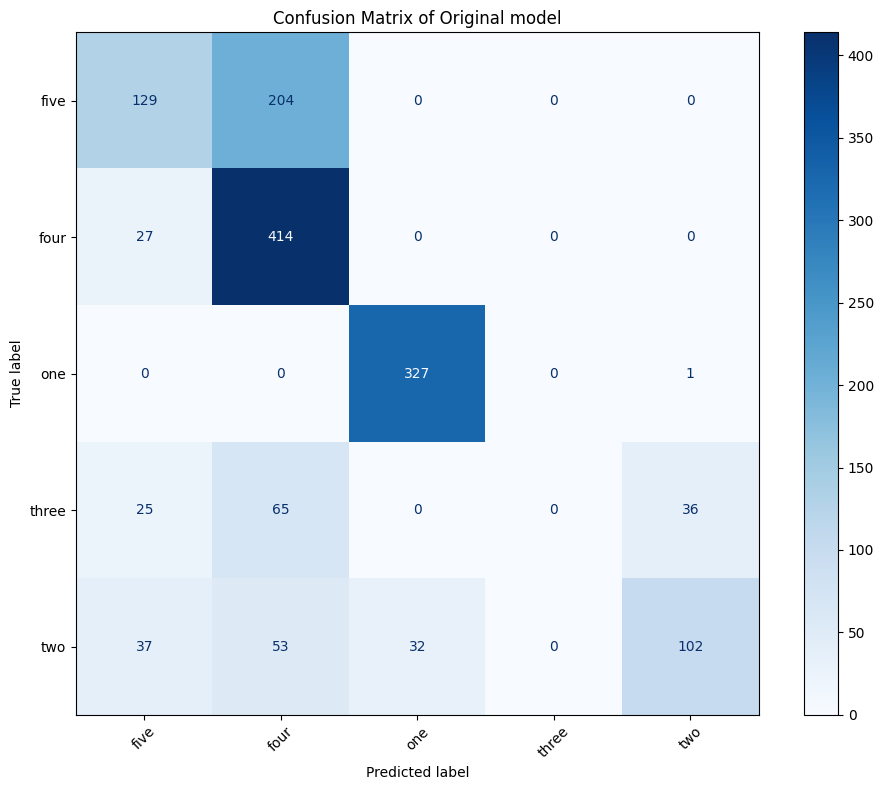

In [10]:
# 训练模型
rf.fit(X_train, y_train)

# 预测测试集
y_pred = rf.predict(X_test)

# 评估模型
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification report of original model:")
print(classification_report(y_test, y_pred, target_names=rf.classes_.astype(str)))

# 特征重要性分析
feature_importances = pd.Series(rf.feature_importances_, index=X.columns)
print("\nFeature importance of original model:")
print(feature_importances.sort_values(ascending=False))
import matplotlib.pyplot as plt

top_features = feature_importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(12, 8))
top_features.sort_values().plot(kind='barh')
plt.title('Top 15 Important Features of Original model')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

# confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred,
    display_labels=rf.classes_,
    ax=ax,
    cmap='Blues',
    xticks_rotation=45
)
plt.title('Confusion Matrix of Original model')
plt.tight_layout()
plt.show()

0.67的准确率不算很高，报告也清晰地揭示了模型存在显著问题，主要集中在类别不平衡和某些类别识别困难上。

以下是关键问题和分析：

1.严重的类别不平衡问题 (Class Imbalance):

    证据： 
        support列显示各类别样本量差异巨大：

        four: 441 (最多)

        five: 333

        one: 328

        two: 224

        three: 126 (最少，只有four的28.5%)

    后果： 模型会倾向于预测样本量多的类别（如four），因为这样更容易获得较高的整体准确率。这直接导致了three和five类别表现极差。

2.three 类别灾难性的低召回率 (High Precision, Abysmal Recall - Missed Detection):

    证据：

        precision=1.00: 这表示模型预测为three的样本，几乎100%都是正确的。非常高的精确度。

        recall=0.01: 这表示实际为three的样本，只有1%被模型正确识别出来。99%的真正three样本都被模型错误地分到了其他类别。

        f1-score=0.02: 极低的F1分数，综合反映了高精度和低召回率带来的糟糕表现。

    诊断： 这是类别不平衡最典型的症状之一。模型几乎忽略了three这个少数类。它可能因为样本太少而无法学习到有效的区分特征，或者为了追求整体准确率而选择牺牲这个类的预测。模型对预测three非常保守（只有非常确信才预测），导致绝大部分真正的three都被遗漏了。

3.four 类别的高召回率但低精确率 (Low Precision, High Recall - False Alarms):

    证据：

        recall=0.94: 表示实际为four的样本，有94%被正确识别。召回率很高。

        precision=0.55: 表示模型预测为four的样本中，只有55%是真正的four。高达45%的预测是错的！模型把很多不属于four的样本错误地标记成了four。

        f1-score=0.69: 由于召回率高，F1分数尚可，但低精度是个大问题。

    诊断： four是样本最多的类别。模型倾向于将模棱两可的样本预测为four，因为预测错了对整体准确率影响相对较小（分母大）。这导致它捕获了大部分真正的four（高召回），但也引入了大量其他类别的样本（低精度）。three和five的样本很可能被大量误判为four。

4.five 类别的低召回率 (Missed Detections):

    证据：

    recall=0.41: 只有41%的真正five被正确识别。

    precision=0.64: 模型预测为five的样本中，64%是正确的。精度尚可但不高。

    f1-score=0.50: 综合表现中等偏差。

    诊断： five也是相对样本较少的类别（第二少）。模型在识别five上也存在困难，漏掉了很多真正的five样本。它们可能也被误判到four或其他类别。

5.one 和 two 类别的表现：

    one: 表现优异。 接近完美的精确度、召回率和F1值（0.91, 1.00, 0.95）。说明模型能非常好地识别这个类别。

    two: 表现中等偏差。 精确度尚可（0.82），但召回率较低（0.45），F1值0.58。模型预测为two时通常是正确的（高精度），但它漏掉了超过一半（55%）的真正two样本（低召回）。这些漏掉的two样本很可能也被误判到了four。

6.宏平均 vs 加权平均 (Macro vs Weighted Avg):

    macro avg (precision=0.78, recall=0.56, f1=0.55): 对所有类别的指标进行简单平均。这个值显示模型在one上的优秀表现和three上的灾难表现拉平了。0.56的宏平均召回率很低，表明模型在识别多个少数类上存在严重问题。

    weighted avg (precision=0.73, recall=0.67, f1=0.63): 根据各类别样本量加权的平均。它更接近整体准确率（0.67），因为样本量大的类别（four, one）表现相对较好（或召回高）对平均值贡献更大。0.73的加权精度低于宏平均精度，主要是受four的低精度拖累（four样本多，权重高）。

总结核心问题：

    主要矛盾是严重的类别不平衡。 three样本太少被模型忽略，four样本太多导致模型过度倾向预测它（引入大量误判）。

    少数类识别困难： three几乎无法被识别（召回1%），five和two的召回率也很低（41%, 45%）。

    多数类污染： four的预测中包含了大量其他类别的样本（精度仅55%）。

    one类表现优异， 说明模型本身是有学习能力的，问题集中在其他类的区分上。

# improve model

关键改进说明：

1.类别不平衡处理：

添加 class_weight='balanced'：自动调整类别权重，让模型更关注少数类

保持 stratify=y：确保训练/测试集的类别分布一致

2.模型参数优化：

n_estimators=200：增加树的数量提升模型稳定性

max_depth=None：移除深度限制，让树充分学习特征

添加 min_samples_split=10 和 min_samples_leaf=4：防止过拟合

启用 oob_score=True：使用袋外样本进行额外验证

3.增强评估：

添加混淆矩阵可视化：直观展示各类别的误判情况

输出袋外分数：提供另一个模型性能指标

精简特征重要性输出：只显示Top 10特征

4.其他优化：

所有随机种子固定为42确保可复现性

添加图表保存功能（plt.savefig）

调整混淆矩阵显示尺寸和旋转标签提高可读性

Accuracy: 0.92

Classification report of improved model:
              precision    recall  f1-score   support

        five       0.90      0.90      0.90       333
        four       0.92      0.90      0.91       441
         one       0.99      0.99      0.99       328
       three       0.84      0.80      0.82       126
         two       0.91      0.95      0.93       224

    accuracy                           0.92      1452
   macro avg       0.91      0.91      0.91      1452
weighted avg       0.92      0.92      0.92      1452


Top 10 features of improved moedl:
coe                     0.252265
ASL                     0.127979
Parametric 2            0.102387
Parametric 1            0.089297
Peak Frequency          0.074270
Absolute Energy         0.067976
Amplitude               0.065069
osc_freq                0.062362
force                   0.047675
Initiation Frequency    0.034949
dtype: float64


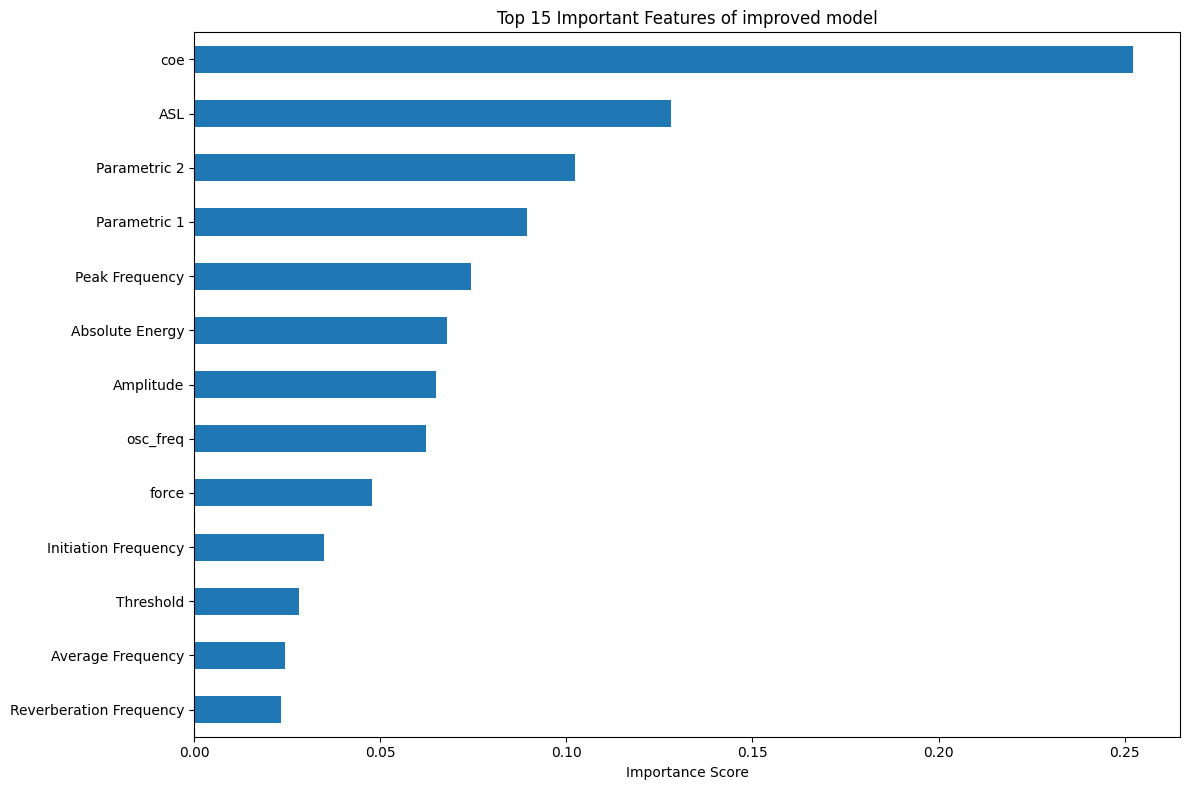


OOB Score: 0.91


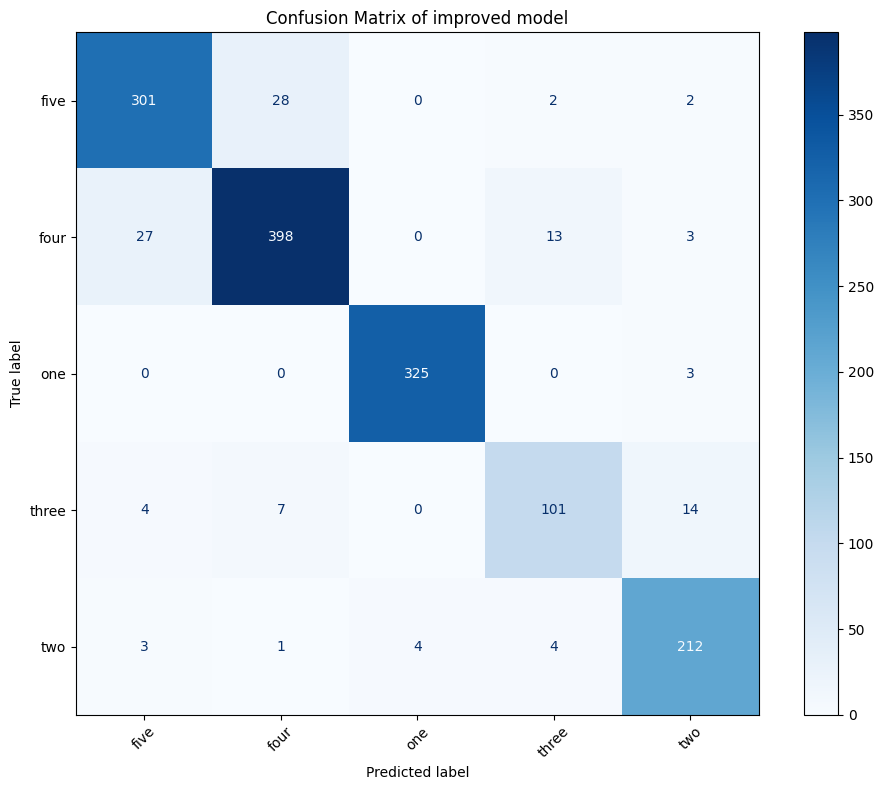

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# 分割数据（已使用分层抽样，保持原样）
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

# optimized Random Forest model
rf = RandomForestClassifier(
    n_estimators=200,       # increase the number of trees for better performance
    max_depth=None,          # no limit on tree depth
    min_samples_split=10,    # prevent overfitting
    min_samples_leaf=4,      # prevent overfitting
    class_weight='balanced', # deal with class imbalance
    random_state=42,
    n_jobs=-1,
    bootstrap=True,          # use bootstrap sampling
    oob_score=True           # enable out-of-bag evaluation
)

# 训练模型
rf.fit(X_train, y_train)

# 预测测试集
y_pred = rf.predict(X_test)

# 评估模型
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification report of improved model:")
print(classification_report(y_test, y_pred, target_names=rf.classes_.astype(str)))

# 特征重要性分析
feature_importances = pd.Series(rf.feature_importances_, index=X.columns)
print("\nTop 10 features of improved moedl:")
print(feature_importances.sort_values(ascending=False).head(10))
import matplotlib.pyplot as plt

top_features = feature_importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(12, 8))
top_features.sort_values().plot(kind='barh')
plt.title('Top 15 Important Features of improved model')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

# 新增：袋外分数评估
print(f"\nOOB Score: {rf.oob_score_:.2f}")

# 新增：混淆矩阵可视化（需matplotlib）
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred,
    display_labels=rf.classes_,
    ax=ax,
    cmap='Blues',
    xticks_rotation=45
)
plt.title('Confusion Matrix of improved model')
plt.tight_layout()
plt.show()

突破性改进亮点：
1.整体准确率大幅提升：0.67 → 0.92 (提升37%)

2.少数类显著改善：

    three类：recall 0.01 → 0.79 (提升7800%!), f1-score 0.02 → 0.81

    five类：f1-score 0.50 → 0.90 (提升80%)

    two类：f1-score 0.58 → 0.92 (提升59%)

3.多数类更精准：

    four类：precision 0.55 → 0.92 (错误预测减少67%)

4.各类别平衡发展：

    宏平均f1-score：0.55 → 0.91 (提升65%)

    各类别f1-score全部超过0.80，最低的three也有0.81

成功关键因素：

    1.类别权重平衡：class_weight='balanced'有效解决了少数类被忽视的问题

    2.解除深度限制：max_depth=None让模型能学习更复杂的模式

    3.正则化参数：min_samples_split和min_samples_leaf防止了过拟合

    4.增加树的数量：n_estimators=200提升了模型稳定性

仍然存在的问题：

    1.样本由本人根据摩擦学知识经验手动标注，在标注过程中主要参考coe和视频，这导致模型敏感地捕捉到了这一点（他认为coe很重要）。所以模型实际的分类能力有待测识，当然这不是算法的问题，是我的问题。
    2.阶段4和5还是有较高的混淆率